# The HF channel

What happens to a 188-110 signal between two radios, as Appendix E of MIL-STD-188-110C
models it, and as our time-varying extension stretches it. The walkthrough
(`walkthrough.ipynb`) follows one message through the modem; this notebook looks at the
channel itself, and at why the standard offers so many modes.

It is generated from `docs/channel.py` (`python tools/build_notebook.py channel`), and the
test suite runs that script. "INT-nnn" refers to `docs/SPEC_NOTES.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from nbtools import QUICK, save_gif

from m110c.channel.watterson import ChannelSpec, WattersonChannel

FS = 9600
plt.rcParams["figure.figsize"] = (8, 3)

## 1. The Watterson model (Appendix E)

Two copies of the signal arrive, a fixed *delay spread* apart (here 2 ms). Each is
multiplied by its own random complex gain: complex Gaussian noise passed through a
Gaussian filter, so its magnitude is Rayleigh-distributed and it changes at a rate set by
the *fading bandwidth* d (the Doppler spread, two sigma: INT-027). A fixed input of 1
through a one-path channel reads that gain out directly. On a 1-Hz channel the path fades
by 10-20 dB every second or two.

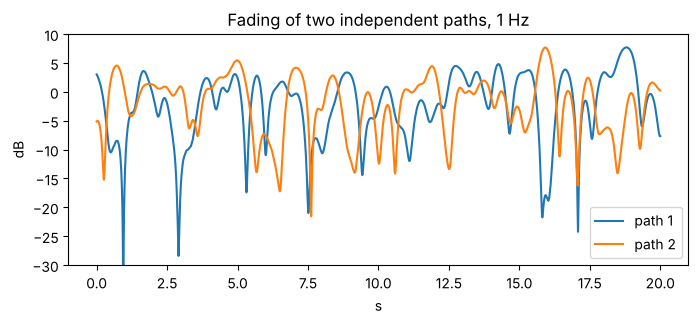

In [2]:
seconds = 10 if QUICK else 20
t = np.arange(seconds * FS) / FS
for seed, label in ((1, "path 1"), (2, "path 2")):
    gain = WattersonChannel(ChannelSpec(1, 0.0, 1.0), seed=seed).process(np.ones(t.size))
    plt.plot(t, 20 * np.log10(np.abs(gain) + 1e-9), label=label)
plt.ylim(-30, 10)
plt.xlabel("s")
plt.ylabel("dB")
plt.title("Fading of two independent paths, 1 Hz")
plt.legend()
plt.show()

The fading's power spectrum should be Appendix E's Gaussian, with standard deviation
d / 2 (E.5.4, INT-027). Averaging the spectrum of the gain over many seconds, it is:

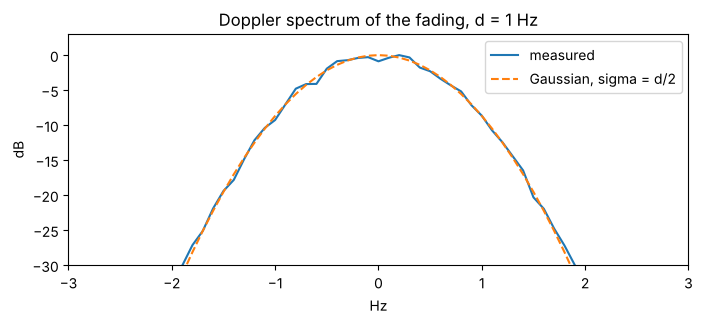

In [3]:
d = 1.0
seconds = 120 if QUICK else 600
gain = WattersonChannel(ChannelSpec(1, 0.0, d), seed=3).process(np.ones(seconds * FS))
rate = 100  # the fading is a few Hz wide: 100 samples per second is plenty
g = gain[:: FS // rate]
n_fft = 10 * rate  # 10-s segments: 0.1-Hz resolution
starts = range(0, g.size - n_fft + 1, n_fft // 2)  # half-overlapping
segments = np.stack([g[i : i + n_fft] for i in starts]) * np.hanning(n_fft)
psd = np.mean(np.abs(np.fft.fftshift(np.fft.fft(segments, axis=1), axes=1)) ** 2, axis=0)
f = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / rate))
theory = np.exp(-(f**2) / (2 * (d / 2) ** 2))
plt.plot(f, 10 * np.log10(psd / psd.max()), label="measured")
plt.plot(f, 10 * np.log10(theory + 1e-12), "--", label="Gaussian, sigma = d/2")
plt.xlim(-3, 3)
plt.ylim(-30, 3)
plt.xlabel("Hz")
plt.ylabel("dB")
plt.title(f"Doppler spectrum of the fading, d = {d:g} Hz")
plt.legend()
plt.show()

### The channel as it changes

The receiver sees the channel as an impulse response: two taps, 2 ms apart, each
rising and falling on its own. Here it is over ten seconds of a 1-Hz channel. The
equaliser's job (see the walkthrough) is to measure these two taps at every probe and
undo them.

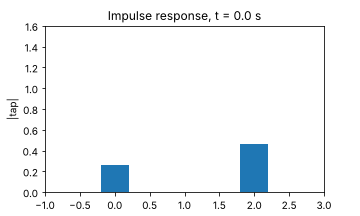

PosixPath('/home/user/MIL-STD-188-110/docs/figures/channel_impulse_response.gif')

In [4]:
spec = ChannelSpec(2, 2.0, 1.0)
L = int(round(spec.delay_ms * 1e-3 * FS))
frames = 40 if QUICK else 100
period = FS // 10  # an impulse every 0.1 s: read both taps from the output
x = np.zeros(frames * period, complex)
x[::period] = 1.0
y = WattersonChannel(spec, seed=4).process(x)
taps = np.stack([y[::period], y[L::period]], axis=1)  # direct, and 2 ms later

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar([0, spec.delay_ms], [0, 0], width=0.4)
ax.set_xlim(-1, 3)
ax.set_ylim(0, 1.6)
ax.set_xlabel("delay (ms)")
ax.set_ylabel("|tap|")
title = ax.set_title("")


def draw(k):
    for bar, h in zip(bars, np.abs(taps[k]), strict=True):
        bar.set_height(h)
    title.set_text(f"Impulse response, t = {k / 10:.1f} s")
    return [*bars, title]


save_gif(FuncAnimation(fig, draw, frames=frames), "channel_impulse_response", fps=10)